# 01.03 · Matrices & linear algebra

**Chapter:** Python & Math for AI · **Milestone:** M1

## Goals
- [ ] Predict the output shape of any matmul at a glance
- [ ] See matrices as transformations; a neural-network layer is `x @ W + b`
- [ ] Use `einsum` for batched operations (attention uses it)
- [ ] Know what SVD gives you (low-rank approximation — the idea behind LoRA)

## Resources
- [Mathematics for Machine Learning (free book), ch. 2-4](https://mml-book.github.io/) — free
- [3Blue1Brown – Essence of linear algebra, ch. 3-4, 14](https://www.3blue1brown.com/topics/linear-algebra) — free

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

## 1. Matrix multiplication and shapes
`(n, k) @ (k, m) -> (n, m)`. Inner dimensions must match and disappear.
Each output entry is a dot product of a row of the left matrix with a column of the right.

In [2]:
A = rng.normal(size=(2, 3))
B = rng.normal(size=(3, 4))
C = A @ B
print(C.shape)
assert np.isclose(C[1, 2], A[1] @ B[:, 2])  # entry (1,2) = row 1 · column 2

(2, 4)


### Why it matters
About 90% of a neural network's compute is matrix multiplication, and most bugs you'll hit in practice are **shape errors**.
Rule: `(n, k) @ (k, m) -> (n, m)`. Inner dimensions must match and disappear.
If you can predict shapes in your head, you can read and debug model code.

## 2. Matrices are transformations
Multiplying points by a matrix moves them: rotation, scaling, shearing, projection.
Below, the unit square is transformed by three matrices.

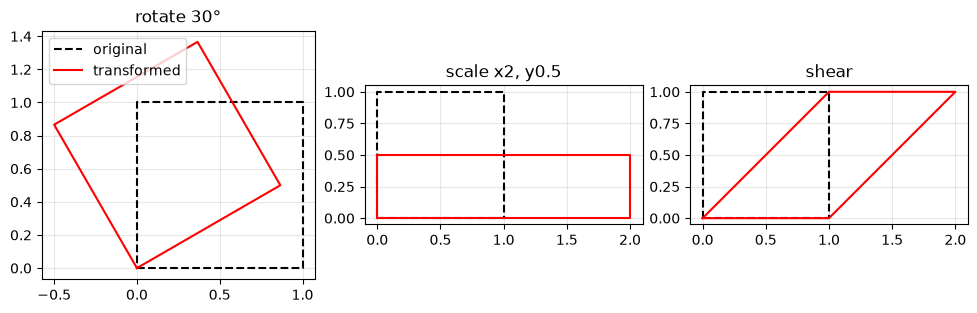

In [3]:
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]], dtype=float)
theta = np.pi / 6
transforms = {
    "rotate 30°": np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]),
    "scale x2, y0.5": np.array([[2, 0], [0, 0.5]]),
    "shear": np.array([[1, 1], [0, 1]]),
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, (name, T) in zip(axes, transforms.items()):
    ax.plot(*square.T, "k--", label="original")
    ax.plot(*(square @ T.T).T, "r-", label="transformed")
    ax.set_title(name); ax.set_aspect("equal"); ax.grid(alpha=0.3)
axes[0].legend(); plt.tight_layout(); plt.show()

### Why it matters
A matrix is a **function that moves points**: it rotates, stretches, squashes or projects them.
This is the core intuition of deep learning: each layer reshapes the data's space until classes or meanings become easy to separate.
Embeddings (chapter 07) are points in such a space; models *learn* the transformations.

## 3. A neural-network layer is a matmul
A linear (dense) layer maps `d_in` features to `d_out` features: `y = x @ W + b`.
With a batch, `x` is `(batch, d_in)`, `W` is `(d_in, d_out)`, `b` broadcasts. That's it.

In [4]:
batch, d_in, d_out = 32, 768, 3072  # GPT-2 MLP sizes
x = rng.normal(size=(batch, d_in))
W = rng.normal(size=(d_in, d_out)) * 0.02
b = np.zeros(d_out)
y = x @ W + b
print(y.shape, "| parameters:", W.size + b.size)

(32, 3072) | parameters: 2362368


### Why it matters
This takes the mystery out of neural nets: a "768 → 3072 layer" is just a 768×3072 matrix of learned numbers.
- Parameter count is `W.size + b.size`, which is how you get "GPT-2 has 124M params".
- It also tells you memory cost: params × 4 bytes in fp32.

## 4. `einsum`: name your dimensions
For batched ops, `einsum` is clearer than juggling transposes. Letters name axes; repeated letters are summed.
Attention scores (chapter 04) are `einsum("bqd,bkd->bqk", Q, K)`: for each batch, every query dotted with every key.

In [5]:
Q = rng.normal(size=(4, 10, 64))  # (batch, queries, dim)
K = rng.normal(size=(4, 12, 64))  # (batch, keys, dim)
scores = np.einsum("bqd,bkd->bqk", Q, K)
assert np.allclose(scores, Q @ K.transpose(0, 2, 1))
print(scores.shape)

(4, 10, 12)


### Why it matters
Transformers do batched, multi-axis matmuls: batch × heads × tokens × dims. With plain `@` you end up juggling transposes.
`einsum` lets you **name each axis** and say which ones get summed.
Attention, the core of every LLM (chapter 04), is `einsum("bhqd,bhkd->bhqk", Q, K)`: every query token dotted with every key token, per head.

⚠️ einsum labels are assigned **by position, not by meaning**. If you put the letters in the wrong order, it still runs and gives a believable shape.
Always check it against a version you trust, e.g. `assert np.allclose(scores, Q @ K.swapaxes(-1, -2))`.

## 5. Solving systems & least squares
Linear regression has a closed-form solution via least squares. Never compute `inv(X.T @ X)` yourself;
use `np.linalg.lstsq` / `solve` (numerically stable).

In [6]:
X = np.c_[np.ones(100), rng.uniform(0, 10, 100)]  # column of ones = intercept
true_w = np.array([2.0, 3.0])
yv = X @ true_w + rng.normal(0, 1, 100)
w_hat, *_ = np.linalg.lstsq(X, yv, rcond=None)
print("true", true_w, "| estimated", w_hat.round(3))

true [2. 3.] | estimated [2.139 2.976]


### Why it matters
Linear regression has an exact solution, so no training loop is needed. Two lessons:
- Many "learning" problems are just "find the `W` that minimizes error". Gradient descent (lesson 05) is the general version, for when no closed form exists.
- **Numerical stability matters.** `inv(X.T @ X)` blows up rounding errors; `lstsq` doesn't. Floats aren't real numbers.

## 6. Eigenvectors & SVD
- **Eigenvectors** of a matrix are directions it only stretches (not rotates). PCA (chapter 02) uses eigenvectors of the covariance matrix.
- **SVD**: any matrix $M = U \Sigma V^T$. Keeping only the top-$r$ singular values gives the best rank-$r$ approximation.
  **LoRA** (chapter 12) fine-tunes models by learning a low-rank update $\Delta W = BA$ — same idea.

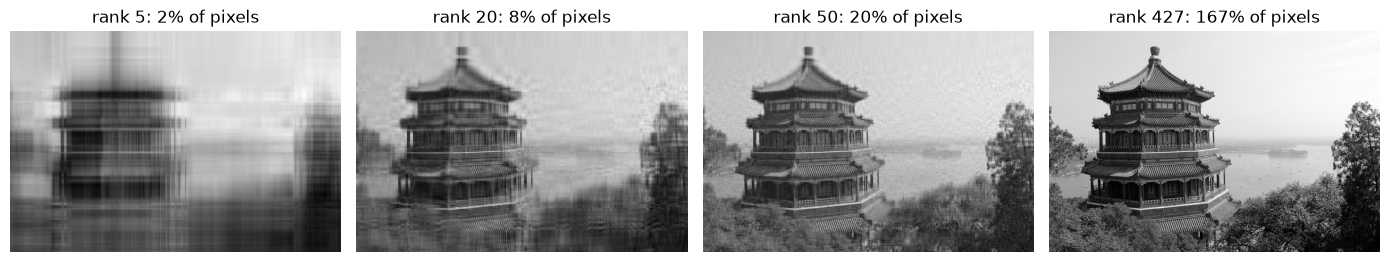

In [7]:
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg").mean(axis=2)  # grayscale, (427, 640)
U, S, Vt = np.linalg.svd(img, full_matrices=False)

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, r in zip(axes, [5, 20, 50, len(S)]):
    approx = U[:, :r] @ np.diag(S[:r]) @ Vt[:r]
    stored = r * (U.shape[0] + Vt.shape[1] + 1)
    ax.imshow(approx, cmap="gray"); ax.axis("off")
    ax.set_title(f"rank {r}: {stored / img.size:.0%} of pixels")
plt.tight_layout(); plt.show()

### Why it matters
SVD shows that most real matrices are **secretly simple**: it splits any matrix into components ranked by importance.
In Exercise 1, about 15 components out of 427 capture most of the image.
- **PCA** (chapter 02): compress data dimensions using the top eigenvectors.
- **LoRA** (chapter 12): the change fine-tuning makes to a weight matrix is also low-rank, so you learn a tiny `B @ A` (≈0.78% of the params, see Exercise 2) instead of the full matrix. That's why you can fine-tune a 7B model on a laptop GPU.

## Exercises
1. Plot relative reconstruction error `‖img - approx‖ / ‖img‖` vs rank (1…200). Where's the elbow?
2. LoRA math: a 4096×4096 weight matrix updated by rank-16 `B @ A`. How many parameters does the update have vs full fine-tuning?
3. Write the attention-score `einsum` for multi-head shapes `(batch, heads, seq, dim)`.

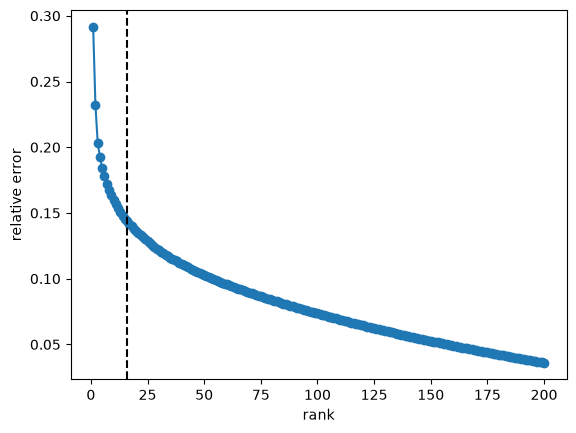

In [17]:
# Exercise 1: Relative reconstruction error vs rank (1…200)
fig, ax = plt.subplots()
ranks = np.arange(1, 201)
img_norm = np.linalg.norm(img)
error = np.array([
    np.linalg.norm(img - (U[:, :k] * S[:k]) @ Vt[:k]) / img_norm
    for k in ranks
])
ax.plot(ranks, error, "o-")
ax.set_xlabel("rank"); ax.set_ylabel("relative error")
ax.axvline(16, color="k", linestyle="--") # elbow at rank 10 is aproximately ~16%, half of the total error.
plt.show()

In [19]:
# Exercise 2: LoRA math
m = 4096
n = 4096
r = 16

# full fine-tuning:
fft = m * n

# LoRA update:
lora_update = r * (m + n)

print(f"full fine-tuning: {fft}")
print(f"LoRA update: {lora_update}")
print(f"Ratio: {100 * lora_update / fft:.2f}% of full fine-tuning") # about 128x less parameters for the same update.

full fine-tuning: 16777216
LoRA update: 131072
Ratio: 0.78% of full fine-tuning


In [21]:
# Exercise 3: Attention score einsum
batch, heads, seq, dim = 4, 12, 1024, 64
Q = rng.normal(size=(batch, heads, seq, dim))
K = rng.normal(size=(batch, heads, seq, dim))
scores = np.einsum("bhqd,bhkd->bhqk", Q, K)
print(scores.shape)
assert np.allclose(scores, Q @ K.transpose(0, 1, 3, 2))

(4, 12, 1024, 1024)


## Takeaway
Exercises 1 and 2 together are **the LoRA argument**:
1. Low rank keeps most of the information. Error drops from 29% to 16% by rank 10; the elbow is around rank 10–20, and after that each extra rank buys little.
2. Low rank costs a tiny fraction of the parameters: 131,072 vs 16,777,216 (0.78%, about 128× fewer).

**Intuition before theory:** watch 3Blue1Brown *Essence of linear algebra* ch. 3–4 (matmul as transformation) and ch. 14 (eigenvectors) before reading the math.